# Day 12 — Customer Segmentation Engine: UCI Online Retail (2010–2011)

**Questions:** which customer groups does this retailer actually have — who is worth protecting, who is slipping away, and who is already gone — and what should it do differently for each group?

**Three hard limits, labelled on every surface:**
1. RFM scores are **relative to this customer base**, not absolute.
2. The data is **2010–2011 — historical**, not today's customers.
3. **14.80% of cleaned revenue has no CustomerID** and cannot be attributed to any segment.

**Decider rule (plan §2.0):** KMeans on log1p + scaled R/F/M is the SOLE decider of segment assignment. RFM scores name and explain; SBC quadrants are a cross-check with the agreement rate reported.

**Attribution:** Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33 — CC BY 4.0. RFM-segmentation source paper: Chen, Sain & Guo (2012).

In [1]:
from pathlib import Path
import json, sqlite3, sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

def _find_root():
    try:
        here = Path(__file__).resolve().parent
    except NameError:
        here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "data" / "processed" / "rfm_table.csv").exists():
            return cand
    raise FileNotFoundError("could not locate data/processed/rfm_table.csv from the notebook location")

ROOT = _find_root()
PROC = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw" / "data.csv"
RAW_XLSX = ROOT / "data" / "raw" / "Online Retail.xlsx"
sys.path.insert(0, str(ROOT))
record = json.loads((PROC / "data_source.json").read_text(encoding="utf-8"))
rfm = pd.read_csv(PROC / "rfm_table.csv")
profile = pd.read_csv(PROC / "segment_profile.csv")
sbc = pd.read_csv(PROC / "sbc_summary.csv")
agreement = pd.read_csv(PROC / "agreement.csv", index_col=0)
print("root:", ROOT)
print("customers:", len(rfm), "| snapshot:", record["rfm"]["snapshot_date"], "| chosen k:", record["chosen_k"])

root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-12-customer-segmentation-engine
customers: 4334 | snapshot: 2011-12-10 | chosen k: 2


## EDA — cleaning audit

Cleaning rules (plan §3.2) applied in order to the 541,909-row raw file; every exclusion counted. Rows with a missing CustomerID stay in the cleaned revenue total but are excluded from RFM — they cannot be attributed to a customer.

In [2]:
counts = record["cleaning_counts_in_order"]
audit = pd.DataFrame([
    ("Raw rows", record["raw_rows"]),
    ("Unparseable dates", counts["n_unparseable_dates"]),
    ("Cancelled rows (C-prefixed invoices)", counts["n_cancelled_rows"]),
    ("Non-positive quantity", counts["n_nonpositive_quantity"]),
    ("Non-positive price", counts["n_nonpositive_price"]),
    ("Non-product adjustment lines", counts["n_adjustment_rows"]),
    ("Missing description", counts["n_missing_description"]),
    ("Cleaned rows", record["cleaned_rows"]),
], columns=["Step", "Rows"])
display(audit)
print("Confirmed date range:", record["confirmed_date_range"])
print("Cleaned revenue: £{:,.2f} | cleaned units: {:,} | orders: {:,}".format(
    record["cleaned_revenue_gbp"], record["cleaned_units"], record["cleaned_orders"]))
print("Missing CustomerID rows:", record["n_missing_customer_id"],
      f"— revenue £{record['revenue_missing_customer_gbp']:,.2f}",
      f"({record['revenue_missing_customer_share']:.2%} of cleaned revenue — unattributed)")
sample = pd.DataFrame(json.loads((ROOT / "data" / "raw" / "sample_rows.json").read_text()))
print("Country mix in the 1,000-row sample:", sample["country"].value_counts().to_dict())
print("Date-format note: the CSV uses M/D/YYYY — parsed with dayfirst=False (see data/README.md).")

,Step,Rows
0,Raw rows,541909
1,Unparseable dates,0
2,Cancelled rows (C-prefixed invoices),9288
3,Non-positive quantity,1336
4,Non-positive price,1181
5,Non-product adjustment lines,2309
6,Missing description,0
7,Cleaned rows,527795


Confirmed date range: ['2010-12-01 08:26:00', '2011-12-09 12:50:00']
Cleaned revenue: £10,283,243.98 | cleaned units: 5,577,139 | orders: 19,776
Missing CustomerID rows: 131455 — revenue £1,522,177.33 (14.80% of cleaned revenue — unattributed)
Country mix in the 1,000-row sample: {'United Kingdom': 917, 'France': 21, 'Germany': 16, 'EIRE': 14, 'Netherlands': 5, 'Australia': 5, 'Norway': 4, 'Portugal': 4, 'Spain': 3, 'Switzerland': 2, 'Sweden': 2, 'Italy': 2, 'Finland': 1, 'Poland': 1, 'Israel': 1, 'Belgium': 1, 'Cyprus': 1}
Date-format note: the CSV uses M/D/YYYY — parsed with dayfirst=False (see data/README.md).


## RFM distributions

Recency in calendar days (snapshot 2011-12-10, range 1–374), Frequency = distinct invoices, Monetary = Σ(Quantity × UnitPrice) in GBP. Scores are percentile-rank 1–5, R inverted, ties sharing a score.

In [3]:
display(rfm[["recency_days", "frequency", "monetary_gbp", "rfm_score"]].describe().round(2))
print("RFM score distribution (3–15):")
print(rfm["rfm_score"].value_counts().sort_index().to_dict())
print("Customers with code 555:", int((rfm["rfm_code"] == 555).sum()),
      "| code 111:", int((rfm["rfm_code"] == 111).sum()))

,recency_days,frequency,monetary_gbp,rfm_score
count,4334.00,4334.00,4334.00,4334.00
mean,93.23,4.25,2021.47,8.85
std,100.18,7.63,8907.50,3.71
min,1.00,1.00,3.75,3.00
25%,18.00,1.00,305.56,6.00
50%,51.00,2.00,668.12,9.00
75%,143.00,5.00,1631.62,12.00
max,374.00,206.00,279138.02,15.00


RFM score distribution (3–15):
{3: 331, 4: 352, 5: 328, 6: 389, 7: 327, 8: 339, 9: 362, 10: 344, 11: 347, 12: 300, 13: 275, 14: 292, 15: 348}
Customers with code 555: 348 | code 111: 331


## k-selection — re-derived, not copied

k = 2..8, KMeans(random_state=42, n_init=10) on log1p + StandardScaler-scaled R/F/M. Rule (plan §4.3): k = argmax silhouette; if two k values are within 0.01, pick the smaller k. Day 10's k = 4 is a precedent, not a prescription.

In [4]:
sel = pd.DataFrame(record["k_selection"])
display(sel)
print("Chosen k:", record["chosen_k"], "| rule:", record["k_selection_rule"])
print("k = 2 silhouette 0.4330 beats k = 3 (0.3374) and k = 4 (0.3339) — the re-derived k differs from Day 10's k = 4.")

,k,sse,silhouette
0,2,6467.466554,0.432954
1,3,4848.821217,0.337401
2,4,3918.578085,0.333923
3,5,3261.784975,0.318238
4,6,2835.985942,0.313070
5,7,2528.808673,0.302863
6,8,2328.184727,0.288474


Chosen k: 2 | rule: k = argmax silhouette over k = 2..8; if two k values are within 0.01 of silhouette, pick the smaller k
k = 2 silhouette 0.4330 beats k = 3 (0.3374) and k = 4 (0.3339) — the re-derived k differs from Day 10's k = 4.


## KMeans segments + naming (the decider)

KMeans decides every assignment; clusters are named from their median RFM-score profile by the fixed prototype rule (plan §4.2). A customer with code 555 is NOT automatically a Champion — only if their KMeans cluster is named Champions.

In [5]:
display(profile)
print("Cluster → name mapping:", record["segment_naming"])
# Decider check: segment column must reproduce from the KMeans labels.
from src.clustering import cluster_customers, name_segments
labels = cluster_customers(rfm, record["chosen_k"])
med = (rfm.assign(kmeans_cluster=labels).groupby("kmeans_cluster")
       .agg(median_r_score=("r_score", "median"), median_f_score=("f_score", "median"),
            median_m_score=("m_score", "median")))
mapping = name_segments(med)
assert (pd.Series(labels).map(mapping).values == rfm["segment"].values).all()
print("Decider check passed: segment == KMeans-label → name mapping for all", len(rfm), "customers.")
# Guarded re-run: if the raw file is present, re-run RFM + KMeans and assert a match.
if RAW.exists() or RAW_XLSX.exists():
    from src.data_pipeline import clean_transactions, load_raw_csv, load_raw_xlsx
    from src.rfm import compute_rfm, score_rfm
    raw = load_raw_csv(RAW) if RAW.exists() else load_raw_xlsx(RAW_XLSX)
    cleaned, _ = clean_transactions(raw)
    snap = pd.Timestamp(record["rfm"]["snapshot_date"])
    rerun = score_rfm(compute_rfm(cleaned, snap))
    merged = rfm.merge(rerun, on="customer_id", suffixes=("", "_rerun"))
    assert (merged["recency_days"] == merged["recency_days_rerun"]).all()
    assert (merged["frequency"] == merged["frequency_rerun"]).all()
    assert np.allclose(merged["monetary_gbp"], merged["monetary_gbp_rerun"], atol=0.01)
    print("Guarded re-run passed: RFM recomputed from the raw file matches the committed table.")
else:
    print("Raw file not present — guarded re-run skipped; committed CSVs used as-is.")

,segment,n_customers,share_customers,revenue_gbp,revenue_share_attributed,revenue_share_total,mean_recency_days,median_recency_days,mean_frequency,median_frequency,mean_monetary_gbp,median_monetary_gbp,mean_rfm_score,median_r_score,median_f_score,median_m_score,action,gbp_at_stake
0,Champions,1661,0.383249,7436335.441,0.848793,0.723151,26.285972,17.0,8.405178,6.0,4477.023143,2044.87,12.797712,4.0,5.0,5.0,Protect them first: VIP retention — early acce...,7436335.441
1,Hibernating,2673,0.616751,1324731.212,0.151207,0.128824,134.823419,97.0,1.661429,1.0,495.597161,358.38,6.403666,2.0,1.0,2.0,Reactivate cheaply or let go: one low-cost rea...,1324731.212
2,Unattributed (no CustomerID),0,0.000000,1522177.330,0.000000,0.148025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,—,1522177.330


Cluster → name mapping: {'0': {'segment': 'Hibernating', 'median_r_score': 2.0, 'median_f_score': 1.0, 'median_m_score': 2.0}, '1': {'segment': 'Champions', 'median_r_score': 4.0, 'median_f_score': 5.0, 'median_m_score': 5.0}}


Decider check passed: segment == KMeans-label → name mapping for all 4334 customers.
Raw file not present — guarded re-run skipped; committed CSVs used as-is.


## SBC cross-check + agreement rate

ADI in weeks (mean inter-order gap ÷ 7), CV² from per-order £ totals, cut-offs 1.32 / 0.49. Single-order customers have no ADI and are excluded from the agreement rate. SBC never overrides a KMeans assignment.

In [6]:
display(sbc)
display(agreement)
print(f"Agreement rate: {record['agreement_rate']:.1%} over {record['n_multi_order_customers']:,} multi-order customers")
print("Method:", record["agreement_method"])
print("Single-order customers:", record["n_single_order_customers"], "(excluded from the agreement denominator)")

,quadrant,n_customers,share_customers,revenue_gbp,revenue_share_attributed
0,Smooth,59,0.013613,186751.610,0.021316
1,Erratic,88,0.020305,1740571.950,0.198671
2,Intermittent,2175,0.501846,4287838.282,0.489420
3,Lumpy,507,0.116982,1916935.140,0.218802
4,Single-order,1505,0.347254,628969.671,0.071791


,Smooth,Erratic,Intermittent,Lumpy,Single-order
segment,,,,,
Champions,24,36,1274,323,4
Hibernating,35,52,901,184,1501


Agreement rate: 51.5% over 2,829 multi-order customers
Method: Greedy best one-to-one segment↔quadrant mapping over multi-order customers only (Single-order excluded); agreement = matched ÷ multi-order customers
Single-order customers: 1505 (excluded from the agreement denominator)


## SQL check + answers to Q1–Q3

The notebook answers count + revenue per segment and the top segment by revenue twice — pandas and in-memory SQLite — and asserts they agree (plan §4.6).

In [7]:
con = sqlite3.connect(":memory:")
rfm.to_sql("rfm", con, index=False)
profile.to_sql("profile", con, index=False)
sql = pd.read_sql_query(
    "SELECT segment, COUNT(*) AS n, SUM(monetary_gbp) AS revenue "
    "FROM rfm GROUP BY segment ORDER BY revenue DESC", con)
display(sql)
for _, row in sql.iterrows():
    prow = profile[profile["segment"] == row["segment"]].iloc[0]
    assert int(row["n"]) == int(prow["n_customers"])
    assert abs(float(row["revenue"]) - float(prow["revenue_gbp"])) < 0.01
top_sql = sql.iloc[0]["segment"]
assert top_sql == profile.iloc[0]["segment"] == "Champions"
print("SQL check passed: counts, revenue and top segment agree with pandas.")
champ = profile[profile["segment"] == "Champions"].iloc[0]
hib = profile[profile["segment"] == "Hibernating"].iloc[0]
print(f"Q1: {len(rfm):,} customers split into {record['chosen_k']} KMeans segments — "
      f"Champions {int(champ['n_customers']):,} ({champ['share_customers']:.1%}) with "
      f"£{champ['revenue_gbp']:,.2f} ({champ['revenue_share_attributed']:.1%} of attributed revenue); "
      f"Hibernating {int(hib['n_customers']):,} ({hib['share_customers']:.1%}) with £{hib['revenue_gbp']:,.2f}.")
print(f"Q2: Champions are worth protecting (median {champ['median_recency_days']:.0f} days, "
      f"{champ['median_frequency']:.0f} orders); Hibernating are already mostly gone "
      f"(median {hib['median_recency_days']:.0f} days, {hib['median_frequency']:.0f} order); "
      f"SBC↔KMeans agreement is only {record['agreement_rate']:.1%}.")
print(f"Q3: one action per segment — VIP retention to protect £{champ['revenue_gbp']:,.2f}; "
      f"one low-cost reactivation email for the £{hib['revenue_gbp']:,.2f} already lapsed.")

,segment,n,revenue
0,Champions,1661,7436335.441
1,Hibernating,2673,1324731.212


SQL check passed: counts, revenue and top segment agree with pandas.
Q1: 4,334 customers split into 2 KMeans segments — Champions 1,661 (38.3%) with £7,436,335.44 (84.9% of attributed revenue); Hibernating 2,673 (61.7%) with £1,324,731.21.
Q2: Champions are worth protecting (median 17 days, 6 orders); Hibernating are already mostly gone (median 97 days, 1 order); SBC↔KMeans agreement is only 51.5%.
Q3: one action per segment — VIP retention to protect £7,436,335.44; one low-cost reactivation email for the £1,324,731.21 already lapsed.


## Charts

All four charts, drawn to scale from the committed tables. Footnotes carry the source, CC BY 4.0 attribution and the historical-data / relative-scores limits.

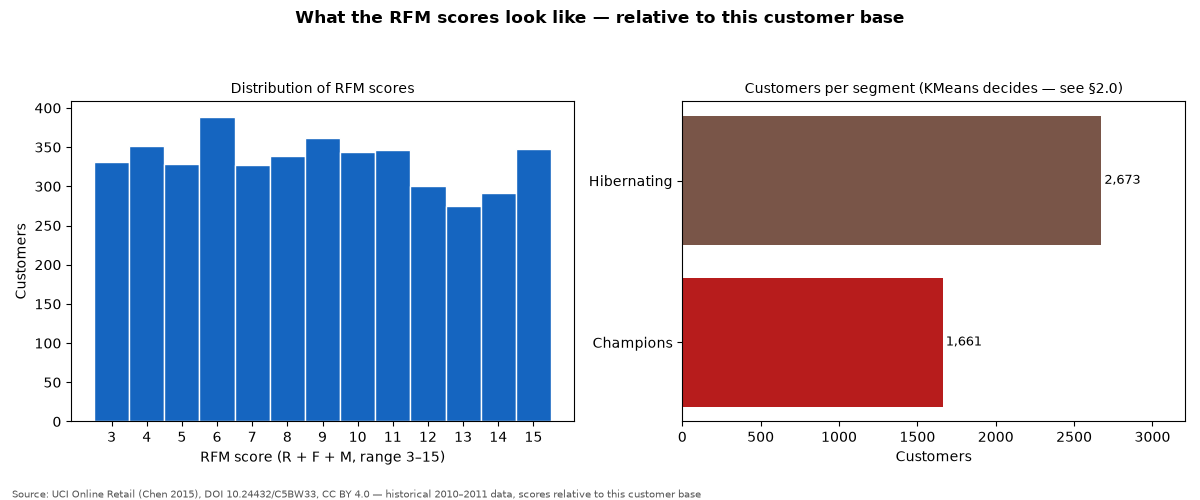

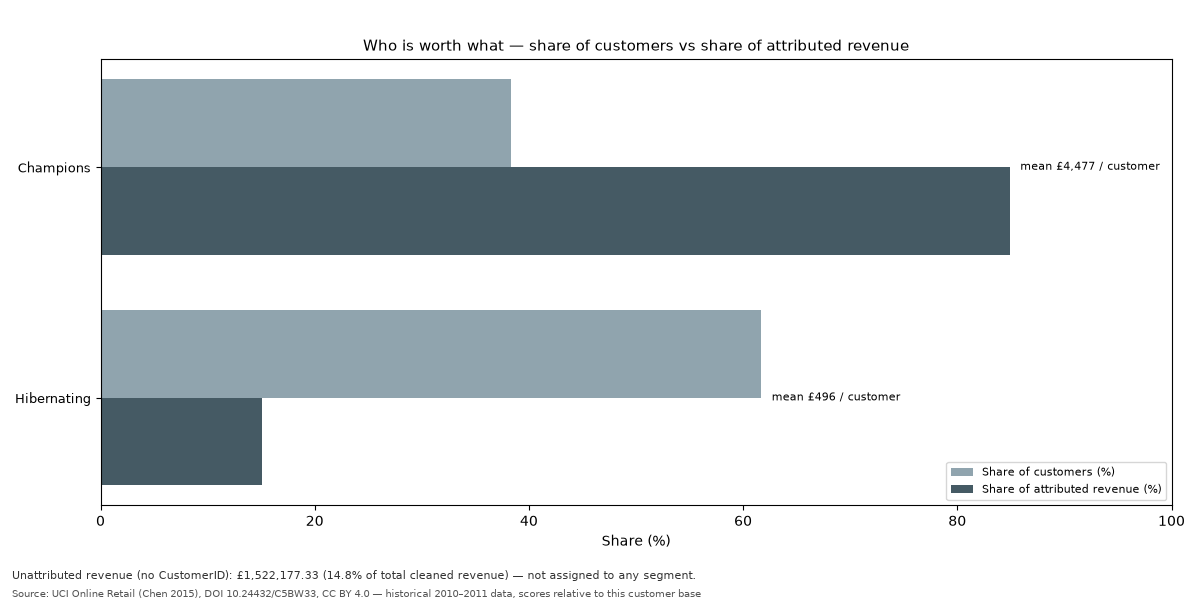

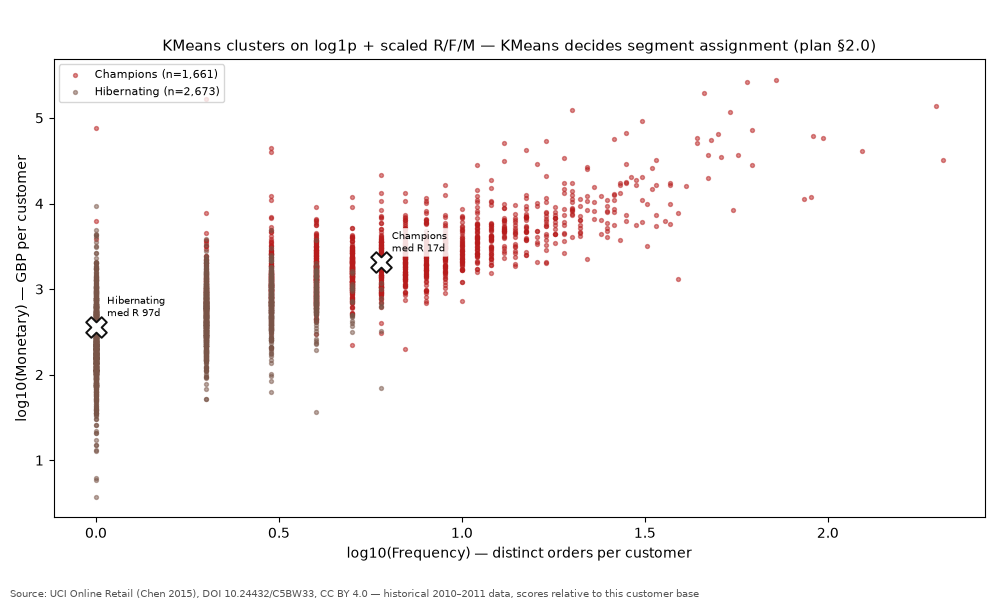

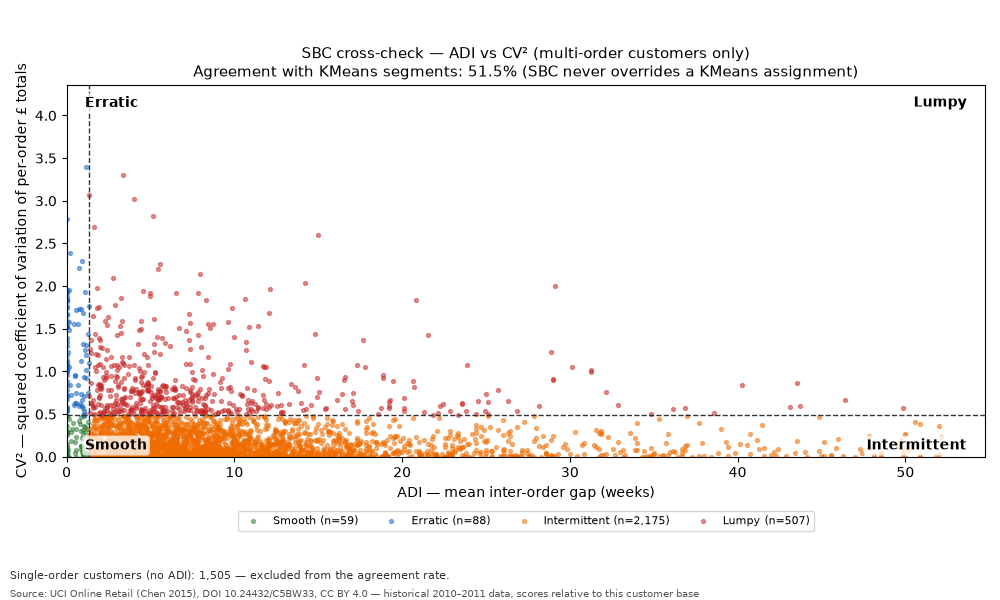

In [8]:
for name in ["01_rfm_scores.png", "02_segment_value.png", "03_kmeans_clusters.png", "04_sbc_quadrants.png"]:
    display(Image(filename=str(ROOT / "outputs" / "charts" / name)))